# 10 - Decision support, robustness, and session merge

This notebook focuses on decision support: compromise solutions, clustering, robustness checks, and merging sessions for downstream analysis. It reuses the results of earlier notebooks instead of simulating them again: the optimisation of notebook 07 and the parametric run of notebook 02, so run those two notebooks first.

The compromise solutions and the clusters only need the results. The robustness check simulates the chosen solutions again with other weather files, so it needs a configured session: the notebook prepares one with the same model, outputs and parameters as notebook 07 and loads the results of notebook 07 into it.

In practical terms, we will move through preparation, configuration, execution, and verification so every transition in the workflow stays explicit.
As the notebook progresses, each code cell is introduced with context first, then the call itself, and finally quick guidance on how to interpret the result.

Workflow roadmap:
- Preparation: imports and the result files of notebooks 07 and 02.
- Configuration: the session of notebook 07 and its results.
- Decision support: compromise solutions, clusters of the non-dominated solutions and robustness against other weather files.
- Session merge: the optimisation and parametric results in one object.

Main classes, methods, and functions used in this notebook:
- `OptimisationSimulation`
- `ParametricSimulation`
- `optim.load_outputs_optimisation`
- `optim.plot_best_compromise_solutions`
- `optim.get_best_compromise_solution`
- `optim.run_clustering`
- `optim.run_robustness_analysis`
- `param_sim.load_outputs_parametric`
- `optim.merge`

Narrative structure used in this notebook:
- Each code cell is preceded by an explanatory markdown block.
- Section headings are contextual to the current notebook and execution block.
- Key arguments are described before they are used in code.
- Execution-oriented cells may include a follow-up markdown note to help interpret results.

## Decision support: import workflow dependencies

We start by importing the APIs required for this notebook block.

Keeping imports explicit at the top of each topic notebook makes selective reruns safer when you jump between sections of the series. The cell also defines `show_plot_output`, a small helper that displays the figures and image files returned by the plotting methods.

What to verify right after running this cell:
- Review execution output and proceed when values look consistent with the workflow intent.

In [1]:
from pathlib import Path

import pandas as pd
from besos import eppy_funcs as ef
from accim.parametric_and_optimisation.main import OptimisationSimulation, ParametricSimulation
from accim.utils import reduce_runtime

# (Run once per notebook)
%matplotlib inline
# If you prefer interaction (zoom/pan), use: %matplotlib widget
from IPython.display import Image, display
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 160)


def show_plot_output(plot_output, image_paths=None):
    # Optional deterministic image display for methods that return tabular data.
    if image_paths is not None:
        if isinstance(image_paths, (str, Path)):
            image_paths = [image_paths]
        for plot_path in image_paths:
            display(Image(filename=str(plot_path)))

    if isinstance(plot_output, dict):
        for plot_path in plot_output.values():
            display(Image(filename=str(plot_path)))
        return
    if isinstance(plot_output, (str, Path)):
        display(Image(filename=str(plot_output)))
        return
    if hasattr(plot_output, "fig"):
        display(plot_output.fig)
        plt.show()
        return
    if hasattr(plot_output, "savefig"):
        display(plot_output)
        plt.show()
        return
    if isinstance(plot_output, pd.DataFrame):
        display(plot_output)
        return
    raise TypeError(f"Unsupported plot output type: {type(plot_output)}")


## Decision support: locate the results of notebooks 07 and 02

This cell locates the most recent result files of notebook 07 (optimisation) and notebook 02 (parametric run). The JSON files are used because they keep the names of the parameters and objectives, which the decision-support methods need.

Variables created in this cell:
- `PROJECT_ROOT`, `OUT_DIR`: working folder and output folder of this notebook.
- `idf_file`, `epw_list`: the model and weather files of notebook 07.
- `optim_json`, `param_json`: result files reused below.

What to verify right after running this cell:
- Confirm that both files are found.

In [2]:
PROJECT_ROOT = Path.cwd()
OUT_DIR = PROJECT_ROOT / "nb10_decision_support_results"
OUT_DIR.mkdir(parents=True, exist_ok=True)

idf_file = "OSM_TestResidentialUnit_v01_onlygeometry_SchNatVent_v2520_high_performance.idf"
epw_list = ["Seville.epw", "Sydney.epw"]

optim_candidates = sorted((PROJECT_ROOT / "nb07_basic_optimization_results").glob("outputs_optimisation_*.json"))
param_candidates = sorted((PROJECT_ROOT / "nb02_parametric_predefined_results").glob("outputs_param_simulation_*.json"))
if not optim_candidates:
    raise FileNotFoundError("No optimisation results were found. Run notebook 07 first.")
if not param_candidates:
    raise FileNotFoundError("No parametric results were found. Run notebook 02 first.")

optim_json = optim_candidates[-1]
param_json = param_candidates[-1]
print("Optimisation results:", optim_json.name)
print("Parametric results:", param_json.name)


Optimisation results: outputs_optimisation_20261015_215103.json
Parametric results: outputs_param_simulation_20261015_214652.json


## Decision support: configure the session of notebook 07

The robustness check simulates solutions again, so it needs the model, the outputs and the parameters of the optimisation. This cell repeats the configuration of notebook 07 (the lighter simulation settings, the two objective meters and the five parameters of the custom model), without running any optimisation.

Key arguments used in this cell and why they matter:
- `reduce_runtime(...)`, `Run_Simulation_for_Sizing_Periods`: the same lighter settings as notebook 07, with the full-year run period.
- `meters`, `match`, `on_missing`: the two objectives of notebook 07.
- `accis_params_dict`: the parameter ranges of notebook 07.
- `minimize_outputs`: both objectives are minimised.

Variables created in this cell:
- `optim`: the configured session.

What to verify right after running this cell:
- Confirm that the two objectives and the five parameters are registered.

In [3]:
building = ef.get_building(idf_file)
reduce_runtime(
    idf_object=building,
    timesteps=2,
    runperiod_begin_month=1,
    runperiod_begin_day_of_month=1,
    runperiod_end_month=12,
    runperiod_end_day_of_month=31,
)
building.idfobjects["SimulationControl"][0].Run_Simulation_for_Sizing_Periods = "No"

optim = OptimisationSimulation(
    buildings=[building],
    parameters_type="accim custom model",
    epws=epw_list,
    output_freqs=["hourly"],
)
df_meters_sel = optim.select_outputs(
    meters=["Heating:Electricity", "Cooling:Electricity"],
    match="case_insensitive",
    on_missing="raise",
)["meters"]
optim.apply_outputs_preflight(
    df_meters_sel=df_meters_sel,
    df_vars_sel=None,
    clean_mode="all",
    validate_before_apply=False,
    validate_after_apply=True,
    on_missing="raise",
)
optim.set_output_readers(df_output_meter=df_meters_sel)
optim.set_parameters(accis_params_dict={
    "CustAST_m": (0.15, 0.95),
    "CustAST_n": (8, 23),
    "CustAST_ASToffset": (1.0, 6.0),
    "CustAST_ASTall": (8, 16),
    "CustAST_ASTaul": (28, 38),
})
optim.set_problem(minimize_outputs=[True, True])
print("Inputs:", optim.problem.names("inputs"))
print("Objectives:", optim.problem.names("outputs"))


Solar distribution has been set to MinimalShadowing.
Shading Calculation Update Frequency was previously set to 20 days, and it has been modified to 20 days.
Maximum Figures in Shadow Overlap Calculations was previously set to 15000 days, and it has been modified to 200 days.
Number of Timesteps per Hour was previously set to 6 days, and it has been modified to 2 days.

--------------------------------------------------------
Adaptive-Comfort-Control-Implemented Model (ACCIM) v0.7.8
--------------------------------------------------------

This tool allows to apply adaptive setpoint temperatures. 
For further information, please read the documentation: 
https://accim.readthedocs.io/en/master/
For a visual understanding of the tool, please visit the following jupyter notebooks:
-    Using addAccis() to apply adaptive setpoint temperatures
https://accim.readthedocs.io/en/master/jupyter_notebooks/addAccis/using_addAccis.html
-    Using rename_epw_files() to rename the EPWs for proper data

VRF Heating Cooling (Northern Hemisphere) Schedule has been added
DefaultFanEffRatioCurve Curve:Cubic Object has been added
VRFTUCoolCapFT Curve:Cubic Object has been added
VRFTUHeatCapFT Curve:Cubic Object has been added
VRFCoolCapFTBoundary Curve:Cubic Object has been added
VRFCoolEIRFTBoundary Curve:Cubic Object has been added
CoolingEIRLowPLR Curve:Cubic Object has been added
VRFHeatCapFTBoundary Curve:Cubic Object has been added
VRFHeatEIRFTBoundary Curve:Cubic Object has been added
HeatingEIRLowPLR Curve:Cubic Object has been added
DefaultFanPowerRatioCurve Curve:Exponent Object has been added
DXHtgCoilDefrostEIRFT Curve:Biquadratic Object has been added
VRFCoolCapFT Curve:Biquadratic Object has been added
VRFCoolCapFTHi Curve:Biquadratic Object has been added
VRFCoolEIRFT Curve:Biquadratic Object has been added
VRFCoolEIRFTHi Curve:Biquadratic Object has been added
VRFHeatCapFT Curve:Biquadratic Object has been added
VRFHeatCapFTHi Curve:Biquadratic Object has been added
VRFHeat

Added - CountHoursNoApp_Floor_2_Residential_Living_Occupants Program
Added - SetGeoVarFloor_2_Residential_Living_Occupants Program
Added - SetInputData Program
Added - SetVOFinputData Program
Added - SetVST Program
Added - ApplyAST_Floor_1_Residential_Living_Occupants Program
Added - ApplyAST_Floor_2_Residential_Living_Occupants Program
Added - Comfort Temperature Output Variable
Added - Adaptive Cooling Setpoint Temperature Output Variable
Added - Adaptive Heating Setpoint Temperature Output Variable
Added - Adaptive Cooling Setpoint Temperature_No Tolerance Output Variable
Added - Adaptive Heating Setpoint Temperature_No Tolerance Output Variable
Added - z_test_ComfStand Output Variable
Added - z_test_ACSTaul Output Variable
Added - z_test_ACSTall Output Variable
Added - z_test_AHSTaul Output Variable
Added - z_test_AHSTall Output Variable
Added - z_test_CAT Output Variable
Added - z_test_ACSToffset Output Variable
Added - z_test_AHSToffset Output Variable
Added - z_test_ComfMod Outp

Solar distribution is already set to MinimalShadowing, therefore no action has been performed.
Shading Calculation Update Frequency was previously set to 20 days, and it has been modified to 20 days.
Maximum Figures in Shadow Overlap Calculations was previously set to 200 days, and it has been modified to 200 days.
Number of Timesteps per Hour was previously set to 2 days, and it has been modified to 2 days.


Inputs: ['CustAST_m', 'CustAST_n', 'CustAST_ASToffset', 'CustAST_ASTall', 'CustAST_ASTaul']
Objectives: ['Heating:Electricity', 'Cooling:Electricity']


## Decision support: load the results of notebook 07

`load_outputs_optimisation` attaches the saved results to the session, as if the optimisation had just run, so the decision-support methods can use them.

Key arguments used in this cell and why they matter:
- `json_path`: the result file of notebook 07.

Variables created in this cell:
- `results_optim`: the loaded results (`optim.outputs_optimisation`).

What to verify right after running this cell:
- Confirm the number of evaluations and of non-dominated solutions.

In [4]:
optim.load_outputs_optimisation(json_path=str(optim_json))
results_optim = optim.outputs_optimisation
print("Evaluations:", len(results_optim))
print("Non-dominated:", int(results_optim["pareto-optimal"].astype(bool).sum()))


  [info] idf_backup_path restored: nb07_basic_optimization_results\accim_idf_backup_OSM_TestResidentialUnit_v01_onlygeometry_SchNatVent_v2520_high_performance_pre_optimisation_20261015_215103.idf
  [info] simulation_summary updated for optimisation after load_outputs_optimisation.
Evaluations: 16
Non-dominated: 10


## Decision support: compromise solutions

The non-dominated solutions of each weather file form a separate front. `plot_best_compromise_solutions` applies multi-criteria decision methods to the front of each weather file: the knee point (the solution closest to the utopia point after min-max normalisation) and TOPSIS (the solution closest to the ideal and farthest from the anti-ideal one, with optional weights per objective). It draws the chosen solutions on each front and returns them in a table.

`get_best_compromise_solution` applies one method in the same way and returns one row per front; it is used below to choose the solution of the robustness check.

Key arguments used in this cell and why they matter:
- `mcdm_configs`: methods applied to each front: `method` (`"knee_point"` or `"topsis"`), optional `weights` of the objectives (heating and cooling electricity) and `label`.
- `normalize_per_m2`: whether results are normalized by floor area.

Variables created in this cell:
- `mcdm_df`: one solution per weather file and method (column `mcdm_method`).

What to verify right after running this cell:
- Compare the solutions chosen by each method on each front.


  [epw=Seville] Best compromise solutions:
    knee_point                | Heating:Electricity=8176.7 kWh | Cooling:Electricity=5352.2 kWh
    topsis                    | Heating:Electricity=8176.7 kWh | Cooling:Electricity=5352.2 kWh
    topsis_w70_30             | Heating:Electricity=1787.0 kWh | Cooling:Electricity=11185.2 kWh

  [epw=Sydney] Best compromise solutions:
    knee_point                | Heating:Electricity=126.1 kWh | Cooling:Electricity=9035.3 kWh
    topsis                    | Heating:Electricity=126.1 kWh | Cooling:Electricity=9035.3 kWh
    topsis_w70_30             | Heating:Electricity=126.1 kWh | Cooling:Electricity=9035.3 kWh

  MCDM summary saved: nb10_decision_support_results\results_mcdm_best_solutions.csv


  MCDM plot saved: nb10_decision_support_results\plot_mcdm_best_solutions.png


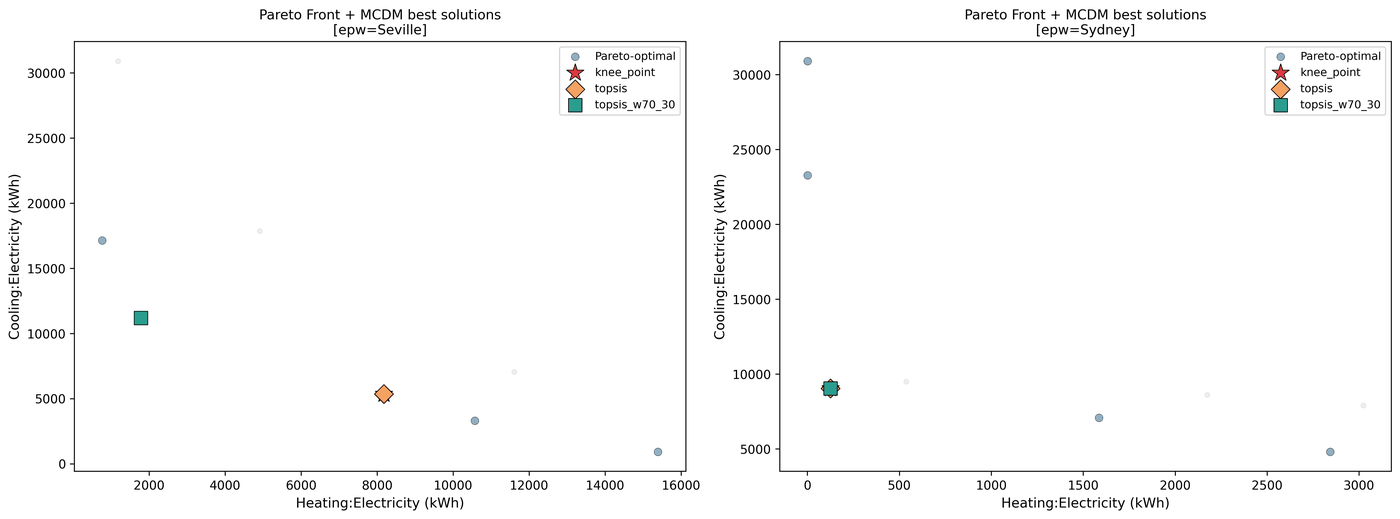

,epw,mcdm_method,CustAST_m,CustAST_n,CustAST_ASToffset,CustAST_ASTall,CustAST_ASTaul
0,Seville,knee_point,0.451,20.210,5.496,15.633,32.361
1,Seville,topsis,0.451,20.210,5.496,15.633,32.361
2,Seville,topsis_w70_30,0.599,11.003,5.678,15.342,28.093
3,Sydney,knee_point,0.710,8.377,5.202,14.682,30.274
4,Sydney,topsis,0.710,8.377,5.202,14.682,30.274
5,Sydney,topsis_w70_30,0.710,8.377,5.202,14.682,30.274


In [5]:
mcdm_df = optim.plot_best_compromise_solutions(
    out_dir=str(OUT_DIR),
    mcdm_configs=[
        {"method": "knee_point"},
        {"method": "topsis"},
        {"method": "topsis", "weights": [0.7, 0.3], "label": "topsis_w70_30"},
    ],
    normalize_per_m2=False,
)
show_plot_output(OUT_DIR / "plot_mcdm_best_solutions.png")
mcdm_df[["epw", "mcdm_method"] + optim.problem.names("inputs")].round(3)


### Reading the result

Open saved figures and verify that filters, grouping, and labels match your intended interpretation.

## Decision support: clusters of the non-dominated solutions

`run_clustering` groups the solutions of each weather file with KMeans, here the non-dominated ones by their parameters, to find families of designs with similar settings.

Key arguments used in this cell and why they matter:
- `n_clusters`: number of clusters.
- `cluster_by`: `"parameters"` or `"objectives"`.
- `pareto_only`: only the non-dominated solutions.
- `out_dir`: output folder.

Variables created in this cell:
- `clusters`: the solutions with their cluster.

What to verify right after running this cell:
- Look at the parameter values of each cluster.

In [6]:
clusters = optim.run_clustering(
    n_clusters=2,
    cluster_by="parameters",
    pareto_only=True,
    out_dir=str(OUT_DIR),
)
clusters


  Clustering complete. Results saved: nb10_decision_support_results\results_clustering.csv


,CustAST_m,CustAST_n,CustAST_ASToffset,CustAST_ASTall,CustAST_ASTaul,Heating:Electricity,Cooling:Electricity,simulation_directory,simulation_output_csv_path,epw,idf,pareto-optimal,Cluster_ID
0,0.598539,11.003156,5.677525,15.341989,28.092900,6.433156e+09,4.026680e+10,nb07_basic_optimization_results\BESOS_Output_1...,nb07_basic_optimization_results\BESOS_Output_1...,Seville,OSM_TestResidentialUnit_v01_onlygeometry_SchNa...,True,1
3,0.412520,11.284147,5.496093,15.637320,28.918965,2.755030e+09,6.168981e+10,nb07_basic_optimization_results\BESOS_Output_1...,nb07_basic_optimization_results\BESOS_Output_1...,Seville,OSM_TestResidentialUnit_v01_onlygeometry_SchNa...,True,1
4,0.450841,20.210192,5.496093,15.633339,32.361396,2.943618e+10,1.926803e+10,nb07_basic_optimization_results\BESOS_Output_3...,nb07_basic_optimization_results\BESOS_Output_3...,Seville,OSM_TestResidentialUnit_v01_onlygeometry_SchNa...,True,0
5,0.598539,19.767320,4.974305,15.391676,31.983554,3.805032e+10,1.191469e+10,nb07_basic_optimization_results\BESOS_Output_3...,nb07_basic_optimization_results\BESOS_Output_3...,Seville,OSM_TestResidentialUnit_v01_onlygeometry_SchNa...,True,0
7,0.811161,20.028099,5.364342,15.817399,32.476996,5.541561e+10,3.322952e+09,nb07_basic_optimization_results\BESOS_Output_3...,nb07_basic_optimization_results\BESOS_Output_3...,Seville,OSM_TestResidentialUnit_v01_onlygeometry_SchNa...,True,0
10,0.362123,8.408096,5.296922,14.505418,30.698040,5.256532e+06,8.378223e+10,nb07_basic_optimization_results\BESOS_Output_1...,nb07_basic_optimization_results\BESOS_Output_1...,Sydney,OSM_TestResidentialUnit_v01_onlygeometry_SchNa...,True,0
11,0.709558,8.377089,5.201997,14.682423,30.274350,4.541185e+08,3.252705e+10,nb07_basic_optimization_results\BESOS_Output_1...,nb07_basic_optimization_results\BESOS_Output_1...,Sydney,OSM_TestResidentialUnit_v01_onlygeometry_SchNa...,True,0
12,0.382404,17.637940,4.212981,11.745146,36.353025,5.710538e+09,2.550590e+10,nb07_basic_optimization_results\BESOS_Output_3...,nb07_basic_optimization_results\BESOS_Output_3...,Sydney,OSM_TestResidentialUnit_v01_onlygeometry_SchNa...,True,1
13,0.274226,8.095539,4.066436,14.578241,28.954814,4.288836e+06,1.112551e+11,nb07_basic_optimization_results\BESOS_Output_3...,nb07_basic_optimization_results\BESOS_Output_3...,Sydney,OSM_TestResidentialUnit_v01_onlygeometry_SchNa...,True,0
15,0.435611,18.555905,4.437542,10.629497,36.627375,1.023614e+10,1.733369e+10,nb07_basic_optimization_results\BESOS_Output_3...,nb07_basic_optimization_results\BESOS_Output_3...,Sydney,OSM_TestResidentialUnit_v01_onlygeometry_SchNa...,True,1


## Decision support: robustness of a solution against other weather files

`run_robustness_analysis` simulates the chosen solutions with each weather file of `epws_robustness` and compares their results, to check whether a solution chosen for one climate keeps performing in others. Here the TOPSIS solution of the Seville front (`get_best_compromise_solution`, equal weights) is simulated with both weather files (two annual simulations): the Seville result repeats the optimisation, and the Sydney result can be compared with the solutions of the Sydney front.

Key arguments used in this cell and why they matter:
- `method`: MCDM method of `get_best_compromise_solution`.
- `optimal_solutions_df`: the solutions to simulate again.
- `epws_robustness`: weather files of the check (file names).
- `out_dir`: output folder.
- `normalize_per_m2`: whether results are normalized by floor area.

Variables created in this cell:
- `sol_topsis`: the TOPSIS solution of each front.
- `sol_seville`: the TOPSIS solution of the Seville front.
- `robustness`: the results of the solution with each weather file.

What to verify right after running this cell:
- Confirm that the Seville result matches the optimisation.
- Compare the Sydney result with the solutions of the Sydney front (`mcdm_df`).

Starting Robustness Analysis: 1 solutions across 2 alternative EPWs.
  Evaluating robustness against EPW: Seville...


Executing:   0%|          | 0/1 [00:00<?, ?row/s]

Running EnergyPlus with stdout output suppressed...


  Evaluating robustness against EPW: Sydney...


Executing:   0%|          | 0/1 [00:00<?, ?row/s]

Running EnergyPlus with stdout output suppressed...


  Robustness plot saved: nb10_decision_support_results\plot_robustness_analysis.png
  Robustness data saved: nb10_decision_support_results\results_robustness.csv


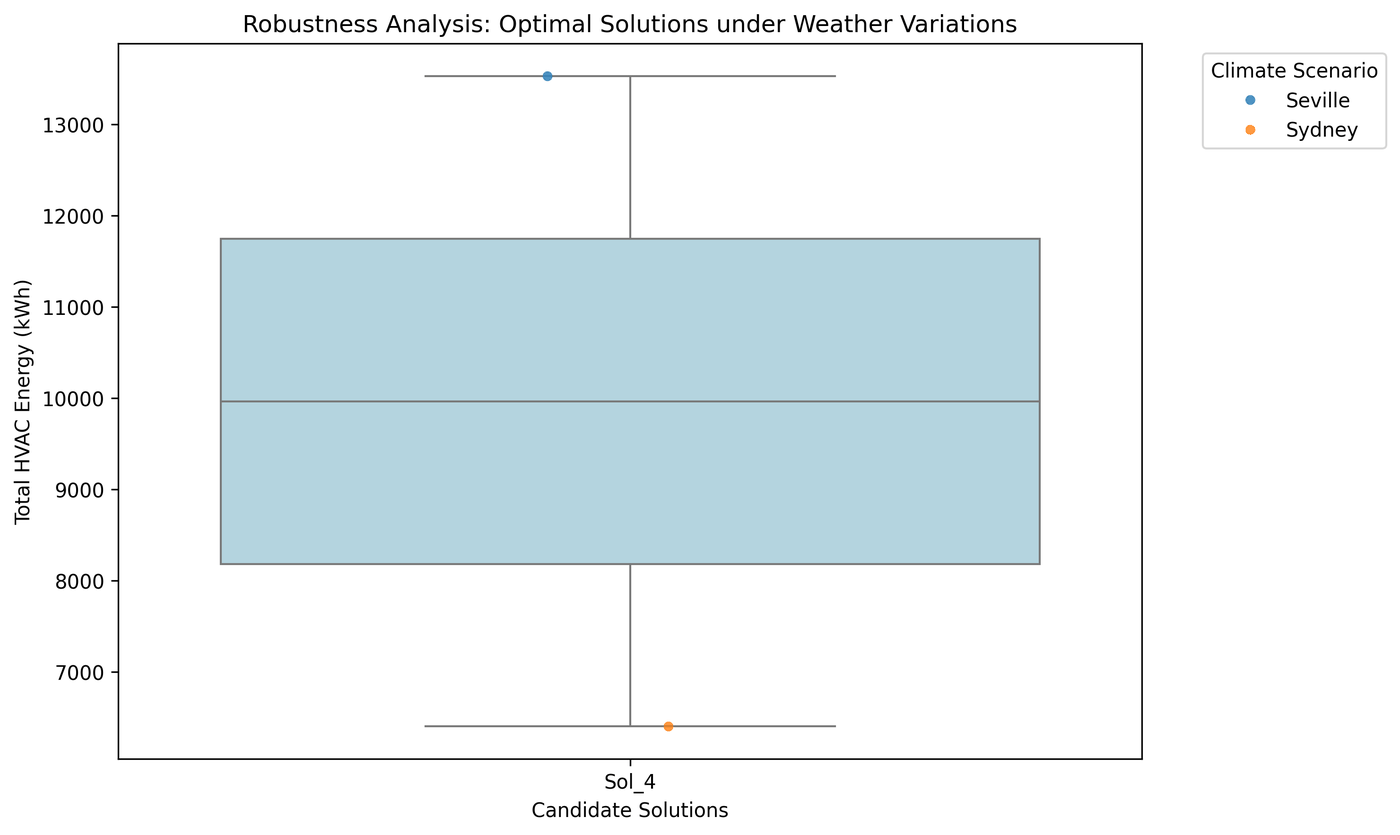

,CustAST_m,CustAST_n,CustAST_ASToffset,CustAST_ASTall,CustAST_ASTaul,Heating:Electricity,Cooling:Electricity,Robustness_EPW,Solution_ID,Total_Energy_kWh
0,0.450841,20.210192,5.496093,15.633339,32.361396,2.943618e+10,1.926803e+10,Seville,Sol_4,13528.948653
1,0.450841,20.210192,5.496093,15.633339,32.361396,1.370882e+10,9.343000e+09,Sydney,Sol_4,6403.284418


In [7]:
sol_topsis = optim.get_best_compromise_solution(method="topsis")
sol_seville = sol_topsis[sol_topsis["epw"] == "Seville"]

robustness = optim.run_robustness_analysis(
    optimal_solutions_df=sol_seville,
    epws_robustness=epw_list,
    out_dir=str(OUT_DIR),
    normalize_per_m2=False,
)
show_plot_output(OUT_DIR / "plot_robustness_analysis.png")
robustness


### Reading the result

Open saved figures and verify that filters, grouping, and labels match your intended interpretation.

## Decision support: load parametric outputs and merge analysis sessions

This block loads the results of notebook 02 into a new `ParametricSimulation` and merges them with the optimisation session, so results of separate work sessions can be analysed together.

Key arguments used in this cell and why they matter:
- `json_path`: result file to load.
- `inplace`: whether merge modifies the current object (`False` returns a new one).

Variables created in this cell:
- `param_sim`: reused in subsequent workflow blocks.
- `merged_obj`: reused in subsequent workflow blocks.

What to verify right after running this cell:
- Validate dataframe dimensions immediately after loading.

In [8]:
param_sim = ParametricSimulation()
param_sim.load_outputs_parametric(json_path=str(param_json))
print("Loaded parametric rows:", len(param_sim.outputs_param_simulation))

merged_obj = optim.merge([param_sim], inplace=False)
print("Merged object type:", type(merged_obj).__name__)


  [info] idf_backup_path restored: nb02_parametric_predefined_results\accim_idf_backup_OSM_TestResidentialUnit_v01_onlygeometry_SchNatVent_v2520_high_performance_pre_parametric_20261015_214623.idf
  [info] simulation_summary updated for parametric after load_outputs_parametric.
Loaded parametric rows: 6


  [info] merge: now 6 parametric rows (+6 from other).
Merged object type: OptimisationSimulation
